In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np


In [2]:
data= pd.read_csv('ipl.csv')

In [3]:
data= pd.DataFrame(data)
data.tail(10)

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
179068,11415,2,Chennai Super Kings,Mumbai Indians,19,3,RA Jadeja,SR Watson,JJ Bumrah,0,...,0,0,0,0,2,0,2,NaN,NaN,NaN
179069,11415,2,Chennai Super Kings,Mumbai Indians,19,4,RA Jadeja,SR Watson,JJ Bumrah,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
179070,11415,2,Chennai Super Kings,Mumbai Indians,19,5,RA Jadeja,SR Watson,JJ Bumrah,0,...,0,0,0,0,2,0,2,NaN,NaN,NaN
179071,11415,2,Chennai Super Kings,Mumbai Indians,19,6,RA Jadeja,SR Watson,JJ Bumrah,0,...,4,0,0,0,4,4,8,NaN,NaN,NaN
179072,11415,2,Chennai Super Kings,Mumbai Indians,20,1,SR Watson,RA Jadeja,SL Malinga,0,...,0,0,0,0,1,0,1,NaN,NaN,NaN
179073,11415,2,Chennai Super Kings,Mumbai Indians,20,2,RA Jadeja,SR Watson,SL Malinga,0,...,0,0,0,0,1,0,1,NaN,NaN,NaN
179074,11415,2,Chennai Super Kings,Mumbai Indians,20,3,SR Watson,RA Jadeja,SL Malinga,0,...,0,0,0,0,2,0,2,NaN,NaN,NaN
179075,11415,2,Chennai Super Kings,Mumbai Indians,20,4,SR Watson,RA Jadeja,SL Malinga,0,...,0,0,0,0,1,0,1,SR Watson,run out,KH Pandya
179076,11415,2,Chennai Super Kings,Mumbai Indians,20,5,SN Thakur,RA Jadeja,SL Malinga,0,...,0,0,0,0,2,0,2,NaN,NaN,NaN
179077,11415,2,Chennai Super Kings,Mumbai Indians,20,6,SN Thakur,RA Jadeja,SL Malinga,0,...,0,0,0,0,0,0,0,SN Thakur,lbw,NaN


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 179078 entries, 0 to 179077
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   match_id          179078 non-null  int64
 1   inning            179078 non-null  int64
 2   batting_team      179078 non-null  str  
 3   bowling_team      179078 non-null  str  
 4   over              179078 non-null  int64
 5   ball              179078 non-null  int64
 6   batsman           179078 non-null  str  
 7   non_striker       179078 non-null  str  
 8   bowler            179078 non-null  str  
 9   is_super_over     179078 non-null  int64
 10  wide_runs         179078 non-null  int64
 11  bye_runs          179078 non-null  int64
 12  legbye_runs       179078 non-null  int64
 13  noball_runs       179078 non-null  int64
 14  penalty_runs      179078 non-null  int64
 15  batsman_runs      179078 non-null  int64
 16  extra_runs        179078 non-null  int64
 17  total_runs        179

# CSK vs MI match 

In [5]:
# analyse Chennai Super Kings vs Mumbai Indians match
match= data[((data['batting_team']=='Chennai Super Kings') &(data['bowling_team']=='Mumbai Indians'))|((data['bowling_team']=='Chennai Super Kings') &(data['batting_team']=='Mumbai Indians'))]

In [6]:
match
inning1=match[match['inning']==1]
inning1.head(10)

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
15486,67,1,Chennai Super Kings,Mumbai Indians,1,1,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,0,1,1,NaN,NaN,NaN
15487,67,1,Chennai Super Kings,Mumbai Indians,1,2,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
15488,67,1,Chennai Super Kings,Mumbai Indians,1,3,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
15489,67,1,Chennai Super Kings,Mumbai Indians,1,4,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
15490,67,1,Chennai Super Kings,Mumbai Indians,1,5,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,4,0,4,NaN,NaN,NaN
15491,67,1,Chennai Super Kings,Mumbai Indians,1,6,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
15492,67,1,Chennai Super Kings,Mumbai Indians,1,7,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,2,0,2,NaN,NaN,NaN
15493,67,1,Chennai Super Kings,Mumbai Indians,2,1,ML Hayden,PA Patel,A Nehra,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
15494,67,1,Chennai Super Kings,Mumbai Indians,2,2,ML Hayden,PA Patel,A Nehra,0,...,0,0,0,0,1,0,1,NaN,NaN,NaN
15495,67,1,Chennai Super Kings,Mumbai Indians,2,3,PA Patel,ML Hayden,A Nehra,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN


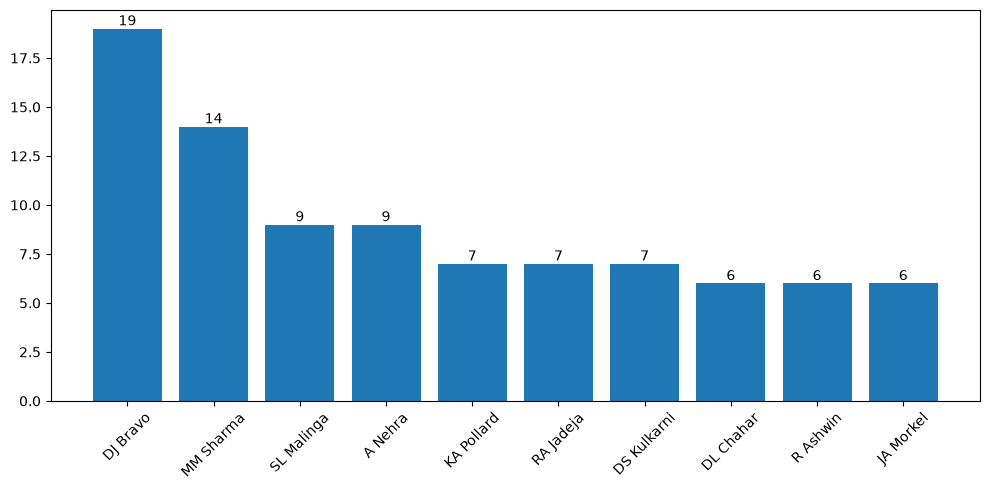

In [7]:
# find wicket fall
inning1['player_dismissed']=inning1['player_dismissed'].fillna('1')
wicket= inning1[inning1['player_dismissed']!='1']
wicket_taken=wicket.groupby('bowler')['player_dismissed'].count().reset_index()
wicket_taken.sort_values('player_dismissed',inplace=True,ascending=False)
wicket_taken=wicket_taken.head(10)

plt.figure(figsize=(10,5))
plt.xticks(rotation=45)
graph=plt.bar(wicket_taken['bowler'],wicket_taken['player_dismissed'])
plt.bar_label(graph)
plt.tight_layout()


 # match score till now 

In [8]:
# match score 
match_score= data.groupby(['match_id','inning','batting_team','bowling_team'])['total_runs'].sum().reset_index()
match_score 

,match_id,inning,batting_team,bowling_team,total_runs
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,207
1,1,2,Royal Challengers Bangalore,Sunrisers Hyderabad,172
2,2,1,Mumbai Indians,Rising Pune Supergiant,184
3,2,2,Rising Pune Supergiant,Mumbai Indians,187
4,3,1,Gujarat Lions,Kolkata Knight Riders,183
...,...,...,...,...,...
1523,11413,2,Delhi Capitals,Sunrisers Hyderabad,170
1524,11414,1,Delhi Capitals,Chennai Super Kings,155
1525,11414,2,Chennai Super Kings,Delhi Capitals,162
1526,11415,1,Mumbai Indians,Chennai Super Kings,152


# winnig teams

In [9]:
# winnig teams till now 
winning_teams= match_score.loc[match_score.groupby('match_id')['total_runs'].idxmax()]
winning_teams

,match_id,inning,batting_team,bowling_team,total_runs
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,207
3,2,2,Rising Pune Supergiant,Mumbai Indians,187
5,3,2,Kolkata Knight Riders,Gujarat Lions,184
7,4,2,Kings XI Punjab,Rising Pune Supergiant,164
8,5,1,Royal Challengers Bangalore,Delhi Daredevils,157
...,...,...,...,...,...
1518,11347,1,Kolkata Knight Riders,Mumbai Indians,143
1521,11412,2,Mumbai Indians,Chennai Super Kings,140
1522,11413,1,Sunrisers Hyderabad,Delhi Capitals,171
1525,11414,2,Chennai Super Kings,Delhi Capitals,162


# avg winning score of a team 

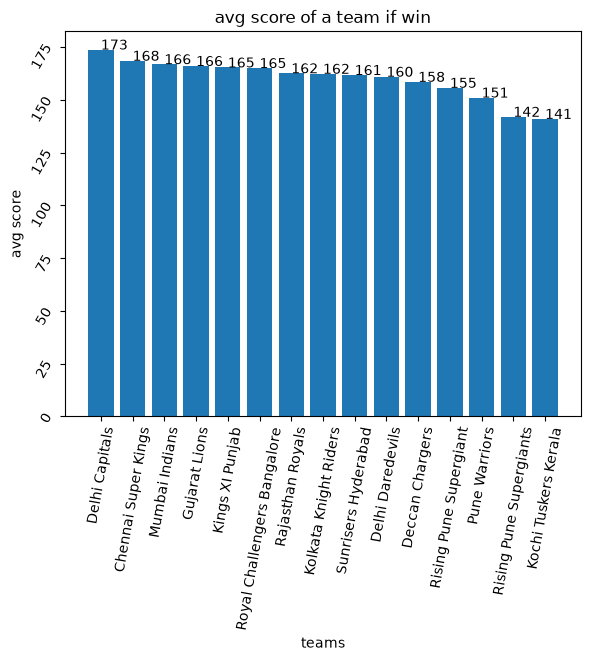

In [10]:
win_avg_score=winning_teams.groupby('batting_team')['total_runs'].mean()
win_avg_score=win_avg_score.sort_values(ascending=False)
win_avg_score=pd.DataFrame(win_avg_score).reset_index()
win_avg_score
plt.bar(win_avg_score['batting_team'],win_avg_score['total_runs'])
plt.xlabel('teams')
plt.ylabel('avg score')
plt.title('avg score of a team if win')
team= win_avg_score['batting_team']
score=win_avg_score['total_runs']
for i in range(len(win_avg_score)):
    plt.text(team[i],score[i],int(score[i]))
    
plt.tight_layout()
plt.yticks(rotation=60)
plt.xticks(rotation=80)
plt.show()

 #Which teams scored the most runs per innings?

Text(0, 0.5, ' avg score ')

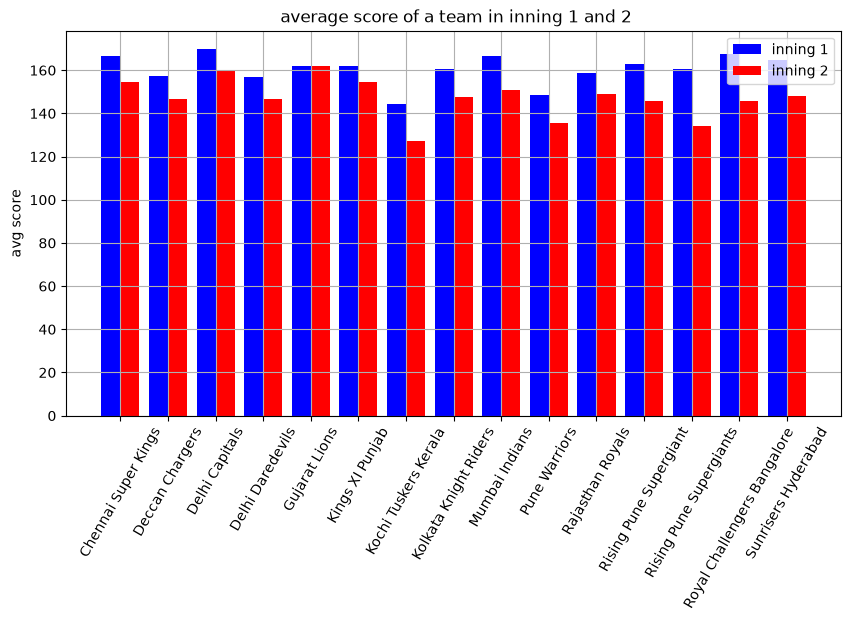

In [11]:
# avg score score of a team as per inning

team_avg= match_score.groupby(['batting_team','inning'])['total_runs'].mean() # match score ko batting team and inning k base pr group kr k avg find kia 
team_avg=pd.DataFrame(team_avg).reset_index() # we found a series so make it dataframe 
# in this current data frame batting team name and innings act as index so do reset index to make them colum
team_avg=team_avg.pivot(index='batting_team',columns='inning',values='total_runs') 
# use pivot method to make some rows to column
team_avg.drop(columns=[3,4,5],inplace=True) # inning 3,4,5 k colum ko drop kia 
plt.figure(figsize=(10,5))
x = np.arange(len(team_avg.index)) # ak hi chart m multi bar k liy batting teams ko kisi number se map kia using numpy 
width=0.4 # bar ki width define ki
plt.bar(x-0.2,team_avg[1],width,label='inning 1' ,color='b') # first chart , x is numerical on x axis and x-0.2 is the point on x axis for bar 
plt.bar(x+0.2,team_avg[2],width,color='r',label='inning 2') # same here 
plt.xticks(x,team_avg.index,rotation=60) # x axis pr number ko team name se replace kia using plt.xtick()
plt.legend() # dono inning ko alg alg mention kia 
plt.grid()
plt.title(' average score of a team in inning 1 and 2')
plt.ylabel(' avg score ')


# batsman performance

In [12]:
player_run= data.groupby('batsman')['total_runs'].sum()
player_run= pd.DataFrame(player_run).sort_values('total_runs', ascending=False)
player_run= player_run[player_run['total_runs']>1500]
player_run
# only 51 player made more then 1500 runs in ipl history 

,total_runs
batsman,
SK Raina,5651
V Kohli,5616
RG Sharma,5057
DA Warner,4975
S Dhawan,4876
CH Gayle,4873
RV Uthappa,4703
MS Dhoni,4691
AB de Villiers,4583


<BarContainer object of 10 artists>

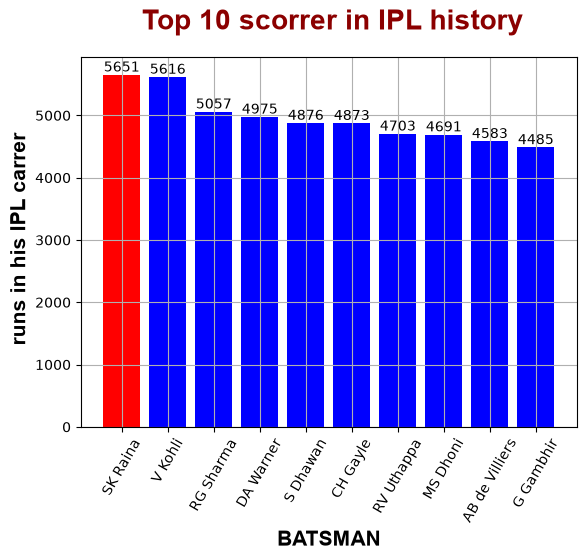

In [13]:
# here player_run batsman is index not colum so make it column using reset_index 
most_runner= player_run.head(10).sort_values('total_runs',ascending=False).reset_index() 
clr=['r','b','b','b','b','b','b','b','b','b']
x=plt.bar(most_runner['batsman'],most_runner['total_runs'],color=clr)
plt.bar_label(x)
plt.xticks(rotation=60)
plt.xlabel('BATSMAN',fontsize=15,fontweight='bold',fontname='Arial')
plt.ylabel(' runs in his IPL carrer',fontsize=15,fontweight='bold',fontname='Arial')
plt.title(' Top 10 scorrer in IPL history',fontsize=20,color='darkred',fontweight='bold',fontname='Arial',pad=20)
plt.grid()
x

In [14]:
# get score of every batsman every match he played
batsman= data.groupby(['batsman','batting_team','match_id','inning','wide_runs']).agg(balls=('bowler','count'),runs=('batsman_runs','sum'))
batsman.reset_index(level=['match_id','inning','wide_runs'],inplace=True)
batsman.head()

match_id  inning  wide_runs  balls  runs
batsman        batting_team                                             
A Ashish Reddy Deccan Chargers       346       1          0     10    10
               Deccan Chargers       352       2          0      3     3
               Deccan Chargers       359       2          0      8     8
               Deccan Chargers       373       2          0      4    10
               Deccan Chargers       376       1          0      4     4

In [15]:
batsman['played_balls']= (batsman['balls']-batsman['wide_runs'])
batsman= batsman[batsman['played_balls']>0]
batsman.drop(columns=['wide_runs','balls'],inplace=True)
batsman=batsman.reset_index(level=['batting_team','batsman'])
batsman

,batsman,batting_team,match_id,inning,runs,played_balls
0,A Ashish Reddy,Deccan Chargers,346,1,10,10
1,A Ashish Reddy,Deccan Chargers,352,2,3,3
2,A Ashish Reddy,Deccan Chargers,359,2,8,8
3,A Ashish Reddy,Deccan Chargers,373,2,10,4
4,A Ashish Reddy,Deccan Chargers,376,1,4,4
...,...,...,...,...,...,...
12382,Z Khan,Royal Challengers Bangalore,307,2,21,21
12383,Z Khan,Royal Challengers Bangalore,317,2,11,7
12384,Z Khan,Royal Challengers Bangalore,326,2,0,3
12385,Z Khan,Royal Challengers Bangalore,367,1,1,3


In [16]:
# strike rate of every batsman to the match he played 
batsman['strike rate']= (batsman['runs']/batsman['played_balls']*100)
batsman

,batsman,batting_team,match_id,inning,runs,played_balls,strike rate
0,A Ashish Reddy,Deccan Chargers,346,1,10,10,100.000000
1,A Ashish Reddy,Deccan Chargers,352,2,3,3,100.000000
2,A Ashish Reddy,Deccan Chargers,359,2,8,8,100.000000
3,A Ashish Reddy,Deccan Chargers,373,2,10,4,250.000000
4,A Ashish Reddy,Deccan Chargers,376,1,4,4,100.000000
...,...,...,...,...,...,...,...
12382,Z Khan,Royal Challengers Bangalore,307,2,21,21,100.000000
12383,Z Khan,Royal Challengers Bangalore,317,2,11,7,157.142857
12384,Z Khan,Royal Challengers Bangalore,326,2,0,3,0.000000
12385,Z Khan,Royal Challengers Bangalore,367,1,1,3,33.333333


 # analyse top score for RCB 

In [17]:
# get all batsman of RCB then do reset index and then drop index column

RCB_batsman= batsman[batsman['batting_team']=='Royal Challengers Bangalore' ].reset_index().drop(columns=['index'])
RCB_batsman.head()

,batsman,batting_team,match_id,inning,runs,played_balls,strike rate
0,A Choudhary,Royal Challengers Bangalore,1,2,6,2,300.000000
1,A Choudhary,Royal Challengers Bangalore,30,1,15,12,125.000000
2,A Choudhary,Royal Challengers Bangalore,42,2,4,6,66.666667
3,A Kumble,Royal Challengers Bangalore,84,1,3,7,42.857143
4,A Kumble,Royal Challengers Bangalore,94,1,0,1,0.000000


                runs
batsman             
V Kohli         5428
AB de Villiers  3751
CH Gayle        3175
JH Kallis       1132
R Dravid         898
PA Patel         752
Mandeep Singh    608
TM Dilshan       587
RV Uthappa       549
LRPL Taylor      517


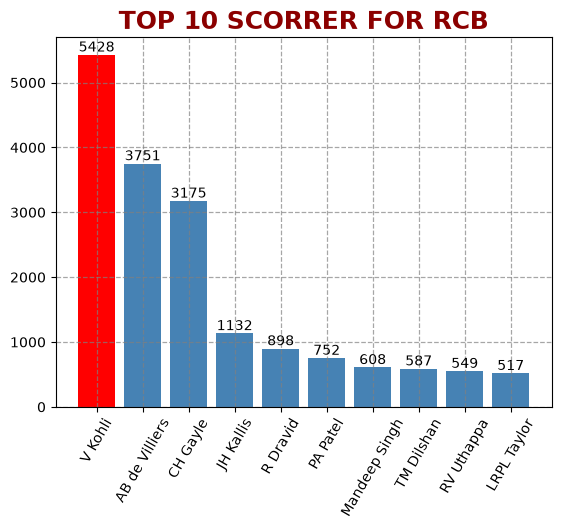

In [18]:
# top scorer 

top_scorer= RCB_batsman.groupby('batsman')['runs'].sum()
top_scorer= pd.DataFrame(top_scorer).sort_values('runs',ascending=False)
top_scorer= top_scorer.head(10)
print(top_scorer)

plt.xticks(rotation=60)
graph= plt.bar(top_scorer.index,top_scorer['runs'],color= ['red']+['steelblue']*(len(top_scorer)-1))
plt.bar_label(graph)
plt.title(' TOP 10 SCORRER FOR RCB ', fontsize=18,color='darkred',fontweight='bold')
plt.grid(color='gray', linestyle='--', linewidth=0.9, alpha=0.7)
plt.show()

               batsman  strike rate
29            DT Patil   237.500000
10            AN Ahmed   225.000000
32     Gurkeerat Singh   173.684211
46            KL Rahul   154.107143
54               M Ali   151.116071
15         BB McCullum   149.428571
98             SN Khan   142.559524
114  Washington Sundar   142.105263
7       AB de Villiers   139.117647
64          MP Stoinis   133.333333


Text(0.5, 1.0, 'TOP STRIKER OF RCB')

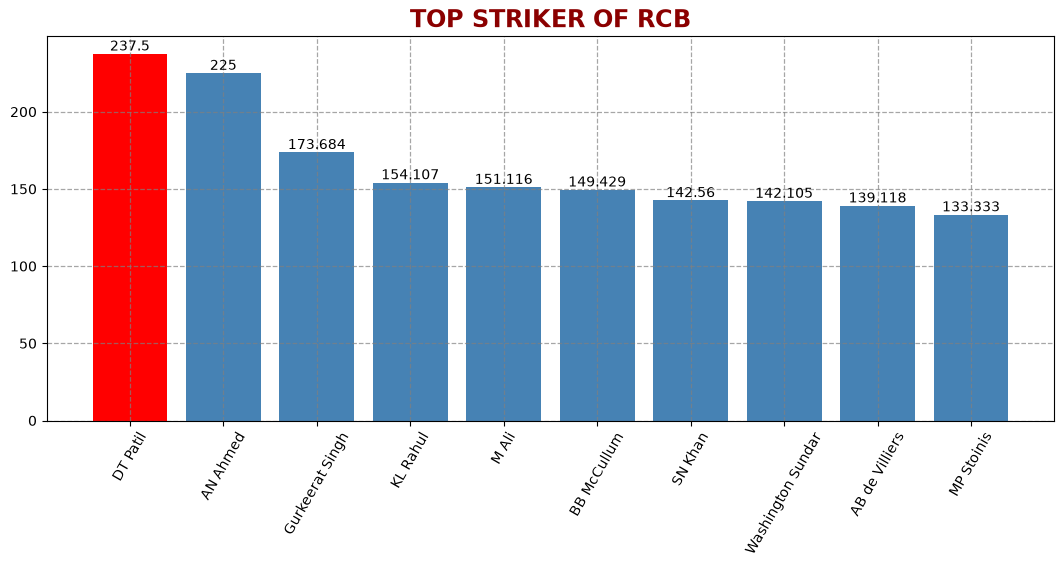

In [19]:
top_striker=RCB_batsman.groupby('batsman')['strike rate'].median()
top_striker=pd.DataFrame(top_striker).reset_index().sort_values('strike rate',ascending=False).head(10)
print(top_striker)

plt.figure(figsize=(13,5))
plt.xticks(rotation=60)
graph=plt.bar(top_striker['batsman'],top_striker['strike rate'],color= ['red']+['steelblue']*(len(top_striker)-1))
plt.bar_label(graph)
plt.grid(color='gray', linestyle='--', linewidth=0.9, alpha=0.7)
plt.title('TOP STRIKER OF RCB',fontsize=17,fontweight='bold', color='darkred')


In [87]:
most6= data[(data['batting_team']=='Royal Challengers Bangalore') & (data['batsman_runs']==6)][['match_id','batsman','batsman_runs']]
most6= most6.groupby('batsman')['batsman_runs'].count()
most6= pd.DataFrame(most6).sort_values('batsman_runs',ascending=False).reset_index().head(10)
most6.rename(columns={'batsman_runs':'total 6'},inplace=True)
most6

,batsman,total 6
0,CH Gayle,240
1,AB de Villiers,201
2,V Kohli,191
3,LRPL Taylor,31
4,RV Uthappa,30
5,Yuvraj Singh,28
6,M Ali,23
7,MA Agarwal,22
8,JH Kallis,21
9,Mandeep Singh,21


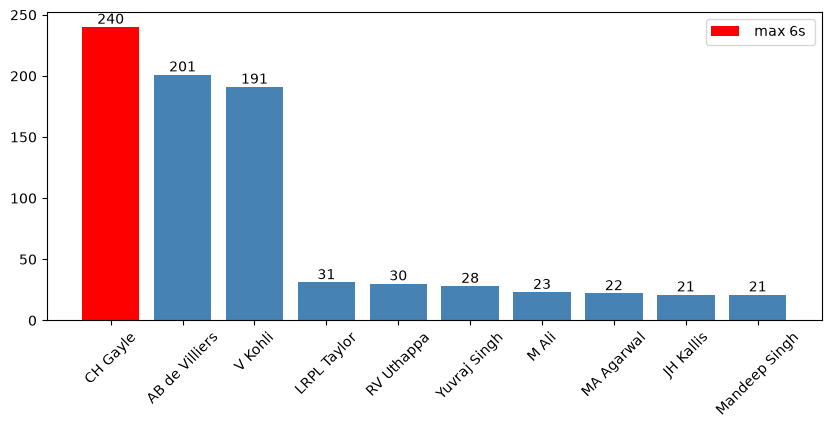

In [101]:
plt.figure(figsize=(10,4))
graph= plt.bar(most6['batsman'],most6['total 6'],color= ['red']+['steelblue']*9,label=' max 6s ')
plt.bar_label(graph)
plt.xticks(rotation=45)
plt.legend()
plt.show()

In [102]:
v_kohali= RCB_batsman[RCB_batsman['batsman']=='V Kohli'].sort_values('runs',ascending=False).head(10)
v_kohali  
# get virat kohli data 

,batsman,batting_team,match_id,inning,runs,played_balls,strike rate
1342,V Kohli,Royal Challengers Bangalore,626,1,113,50,226.000000
1340,V Kohli,Royal Challengers Bangalore,620,1,109,55,198.181818
1337,V Kohli,Royal Challengers Bangalore,611,2,108,58,186.206897
1334,V Kohli,Royal Challengers Bangalore,595,1,100,63,158.730159
1369,V Kohli,Royal Challengers Bangalore,11326,1,100,58,172.413793
1290,V Kohli,Royal Challengers Bangalore,438,1,99,58,170.689655
1288,V Kohli,Royal Challengers Bangalore,432,2,93,47,197.872340
1349,V Kohli,Royal Challengers Bangalore,7907,2,93,62,150.000000
1365,V Kohli,Royal Challengers Bangalore,11153,1,84,49,171.428571
1322,V Kohli,Royal Challengers Bangalore,562,1,82,50,164.000000


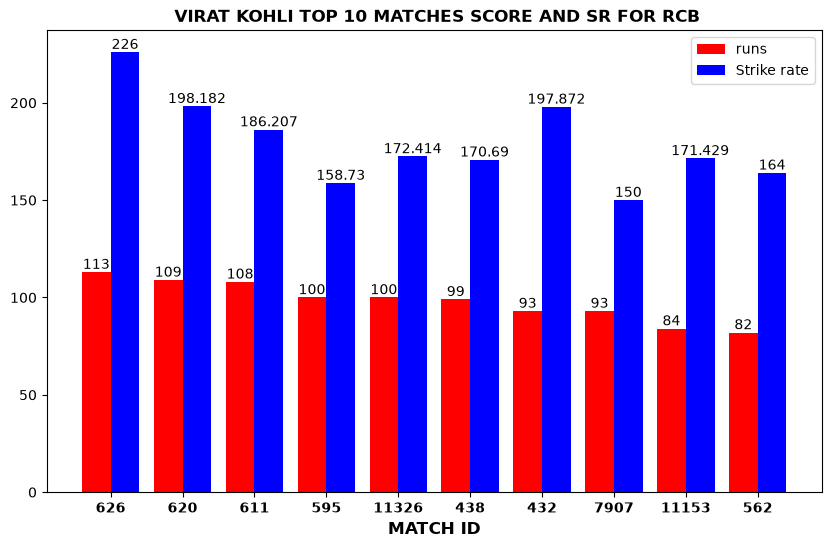

In [103]:
plt.figure(figsize=(10,6))  # define size of chart 
x= np.arange(len(v_kohali['match_id'])) # we want to draw two graph at one chart so give x axis values a numeric number to handle position 
width= 0.4 # width of bar 
runs=plt.bar(x-0.2,v_kohali['runs'],width,color='r',label= 'runs') # first chart for runs 
strike=plt.bar(x+0.2,v_kohali['strike rate'],width,color='b', label='Strike rate') # second chart for strike rate
plt.bar_label(runs) # give run bar its original value 
plt.bar_label(strike) # give strike bar its original value to every
plt.xticks(x,v_kohali['match_id'],fontweight= 'bold') # x axis k numeric index ko renam ekia 
plt.title(' VIRAT KOHLI TOP 10 MATCHES SCORE AND SR FOR RCB', fontsize=12, fontweight='bold')
plt.xlabel(' MATCH ID ', fontsize=12, fontweight='bold')
plt.legend()

In [166]:
RCB= data[data['batting_team']=='Royal Challengers Bangalore']
RCB = RCB.fillna(0)
RCB= RCB[RCB['player_dismissed']!= 0]

# wicket loss in first 6 overs 

RCB_first6= RCB[RCB['over']<=6]
RCB_first6= RCB_first6.groupby('match_id')['player_dismissed'].count()
RCB_first6=pd.DataFrame(RCB_first6)
RCB_first6=RCB_first6.reset_index().sort_values('player_dismissed',ascending=False).head(50)
RCB_first6= RCB_first6.rename(columns={'player_dismissed':'first 6'})
RCB_first6

,match_id,first 6
145,11340,7
88,471,5
122,633,5
89,475,4
4,27,4
11,60,4
109,568,4
15,76,3
17,84,3
9,45,3


In [165]:
# wicket loos in 7 to 15 over 
RCB_first15= RCB[(RCB['over']>6) & (RCB['over']<=15)]
RCB_first15= RCB_first15.groupby('match_id')['player_dismissed'].count()
RCB_first15=pd.DataFrame(RCB_first15)
RCB_first15=RCB_first15.reset_index().sort_values('player_dismissed',ascending=False).head(50)
RCB_first15= RCB_first15.rename(columns={'player_dismissed':'7 to 15'})
RCB_first15

,match_id,7 to 15
26,122,7
6,27,6
53,231,6
139,7928,6
144,11137,6
86,417,6
64,296,5
14,70,5
19,90,5
12,60,5


In [164]:
# last  5 overs 

RCB_last6= RCB[RCB['over']>15]
RCB_last6= RCB_last6.groupby('match_id')['player_dismissed'].count()
RCB_last6=pd.DataFrame(RCB_last6)
RCB_last6=RCB_last6.reset_index().sort_values('player_dismissed',ascending=False).head(50)
RCB_last6= RCB_last6.rename(columns={'player_dismissed':'last 5 over'})

RCB_last6

,match_id,last 5 over
14,74,7
62,320,7
46,220,6
17,84,6
93,525,6
80,441,6
44,209,5
3,17,5
0,1,5
74,401,5


In [ ]:
 # now merge all three data Frame on the bassis of inex means match id

In [167]:
wicket_fall= pd.merge(RCB_first6,RCB_first15, on='match_id'),RCB_last6,on='ma
wicket_fall

,match_id,first 6,7 to 15
0,471,5,5
1,475,4,3
2,27,4,6
3,60,4,5
4,317,3,4
5,101,3,4
6,30,3,4
7,42,3,4
8,296,3,5
9,11147,3,3
